Using packages from week 41 

In [1]:
%pip install -q scanpy igraph scikit-misc


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot
import numpy
import pandas
import scanpy
import scipy.sparse
import scipy.stats

# Keep the output readable: hide harmless version warnings.
warnings.filterwarnings('ignore')

# Reproducibility: many steps use random numbers (PCA solver, UMAP, Leiden).
# Fixing the seed means that you and your neighbour get the same picture.
numpy.random.seed(0)

# Plot defaults: figure size in inches, resolution, white background.
scanpy.settings.set_figure_params(dpi=80, figsize=(4, 4), facecolor='white')

# Print the versions of everything we use. Always do this in a real analysis,
# and paste it in your methods section.
scanpy.logging.print_header()

Package,Version
matplotlib,3.11.2
numpy,2.5.2
pandas,3.0.5
scanpy,1.12.4
scipy,1.18.1
Component,Info
Python,"3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]"
OS,Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
CPU,"8/8 logical CPU cores, x86_64"
GPU,No GPU found


load the data, using data code from week 41 

In [3]:
import os
import tarfile
import urllib.request

TENX_URL = 'https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz'


def load_pbmc3k():
    # Attempt 1: scanpy's own copy of the data (a single .h5ad file, 6 MB).
    try:
        return scanpy.datasets.pbmc3k()
    except Exception as error:
        print('Attempt 1 (scanpy dataset) failed:', repr(error)[:200])

    # Attempt 2: the original 10x tarball, read as a 10x matrix folder.
    try:
        os.makedirs('data', exist_ok=True)
        archive = os.path.join('data', 'pbmc3k_10x.tar.gz')
        urllib.request.urlretrieve(TENX_URL, archive)
        with tarfile.open(archive) as handle:
            handle.extractall('data')
        return scanpy.read_10x_mtx('data/filtered_gene_bc_matrices/hg19/', var_names='gene_symbols')
    except Exception as error:
        print('Attempt 2 (10x download) failed:', repr(error)[:200])

    # Attempt 3: a file you uploaded yourself.
    if os.path.exists('pbmc3k_raw.h5ad'):
        return scanpy.read_h5ad('pbmc3k_raw.h5ad')

    raise RuntimeError(
        'Could not get the data automatically. Ask the teacher for pbmc3k_raw.h5ad, '
        'upload it with the folder icon on the left of Colab (it must end up next to this notebook), '
        'and run this cell again.'
    )


adata = load_pbmc3k()

# Gene symbols are not guaranteed to be unique. Make them unique (adds -1, -2 to duplicates).
adata.var_names_make_unique()

# Keep an untouched copy of the counts. We use it later in the play-time section
# so that we never have to download the data twice.
adata_counts = adata.copy()

print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)


In [4]:
def run_pipeline(
    adata_counts,
    min_genes=200,
    min_cells=3,
    max_genes=2500,
    max_pct_mt=5.0,
    n_top_genes=2000,
    n_pcs=40,
    n_neighbors=10,
    resolution=0.7,
    regress=False,
    seed=0,
):
    # Start from the untouched counts every time.
    data = adata_counts.copy()

    # Section 4: quality control.
    scanpy.pp.filter_cells(data, min_genes=min_genes)
    scanpy.pp.filter_genes(data, min_cells=min_cells)
    data.var['mt'] = data.var_names.str.startswith('MT-')
    scanpy.pp.calculate_qc_metrics(data, qc_vars=['mt'], inplace=True)
    data = data[data.obs['n_genes_by_counts'] < max_genes, :].copy()
    data = data[data.obs['pct_counts_mt'] < max_pct_mt, :].copy()

    # Sections 6 and 7: normalize, log, HVGs.
    data.layers['counts'] = data.X.copy()
    scanpy.pp.normalize_total(data, target_sum=1e4)
    scanpy.pp.log1p(data)
    try:
        scanpy.pp.highly_variable_genes(data, layer='counts', n_top_genes=n_top_genes, flavor='seurat_v3')
    except ValueError:
        # With very few cells the curve fit of seurat_v3 can fail. Fall back to the classic method
        # (it works on the log-normalized values, which is what data.X holds at this point).
        print('seurat_v3 failed (too few cells for the curve fit), using flavor=seurat instead')
        scanpy.pp.highly_variable_genes(data, n_top_genes=n_top_genes, flavor='seurat')
    data.raw = data
    data = data[:, data.var['highly_variable']].copy()

    # Section 8: the optional regression the tutorial has, then scaling and PCA.
    if regress:
        scanpy.pp.regress_out(data, ['total_counts', 'pct_counts_mt'])
    scanpy.pp.scale(data, max_value=10)
    scanpy.tl.pca(data, svd_solver='arpack', random_state=seed)

    # Sections 9 and 10: graph, map, clusters.
    scanpy.pp.neighbors(data, n_neighbors=n_neighbors, n_pcs=n_pcs, random_state=seed)
    scanpy.tl.umap(data, random_state=seed)
    scanpy.tl.leiden(data, resolution=resolution, random_state=seed, flavor='igraph', n_iterations=2, directed=False)

    return data


# Sanity check: with the defaults, it must give the same number of cells and clusters as above.
baseline = run_pipeline(adata_counts)
print('cells:', baseline.n_obs, '   clusters:', baseline.obs['leiden'].nunique())

cells: 2638    clusters: 8


In [5]:
result_03 = run_pipeline(adata_counts, resolution=0.3)
result_07 = run_pipeline(adata_counts, resolution=0.7)
result_1_5 = run_pipeline(adata_counts, resolution=1.5)

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

figures_dir = Path("results/module1")
figures_dir.mkdir(parents=True, exist_ok=True)

Number of Leiden clusters: 6


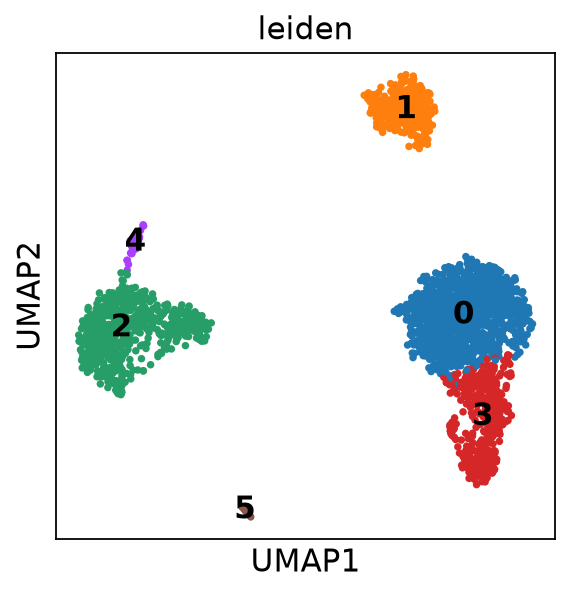

Number of Leiden clusters: 8


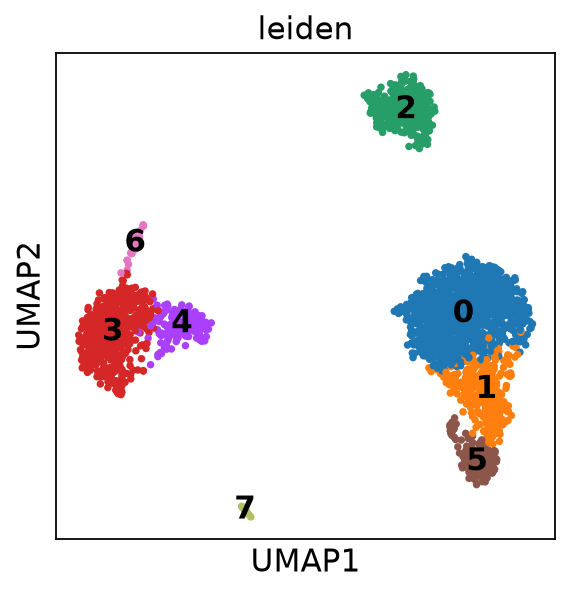

Number of Leiden clusters: 13


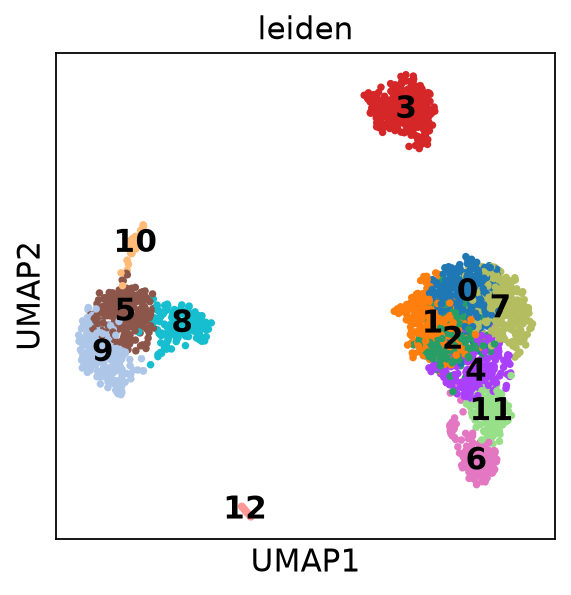

In [11]:
n_clusters_03 = result_03.obs['leiden'].nunique()
print("Number of Leiden clusters:", n_clusters_03)

figure03 =scanpy.pl.umap(
    result_03,
    color='leiden',
    legend_loc='on data',
    return_fig=True
)

figure03.figure.savefig(
    figures_dir / "UMAP_resolution_0.3.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(figure03.figure)

n_clusters_07 = result_07.obs['leiden'].nunique()
print("Number of Leiden clusters:", n_clusters_07)

figure07 =scanpy.pl.umap(
    result_07,
    color='leiden',
    legend_loc='on data',
    return_fig=True
)
figure07.figure.savefig(
    figures_dir / "UMAP_resolution_0.7.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(figure07.figure)

n_clusters_1_5 = result_1_5.obs['leiden'].nunique()
print("Number of Leiden clusters:", n_clusters_1_5)
figure1_5 = scanpy.pl.umap(
    result_1_5,
    color='leiden',
    legend_loc='on data',
    return_fig=True
)
figure1_5.figure.savefig(
    figures_dir / "UMAP_resolution_1.5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

In [8]:
marker_genes = {
    'CD4 T': ['IL7R', 'CD3D'],
    'CD8 T': ['CD8A', 'CD8B'],
    'NK': ['GNLY', 'NKG7'],
    'B': ['MS4A1', 'CD79A'],
    'CD14 Mono': ['CD14', 'LYZ'],
    'FCGR3A Mono': ['FCGR3A', 'MS4A7'],
    'DC': ['FCER1A', 'CST3'],
    'Platelets': ['PPBP', 'PF4'],
}

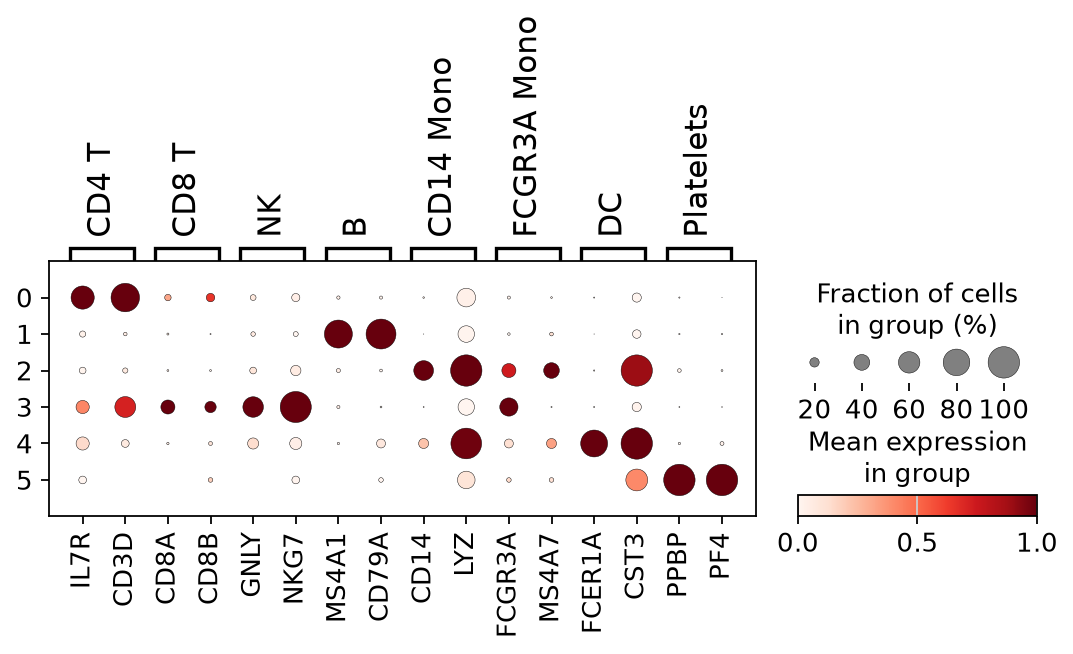

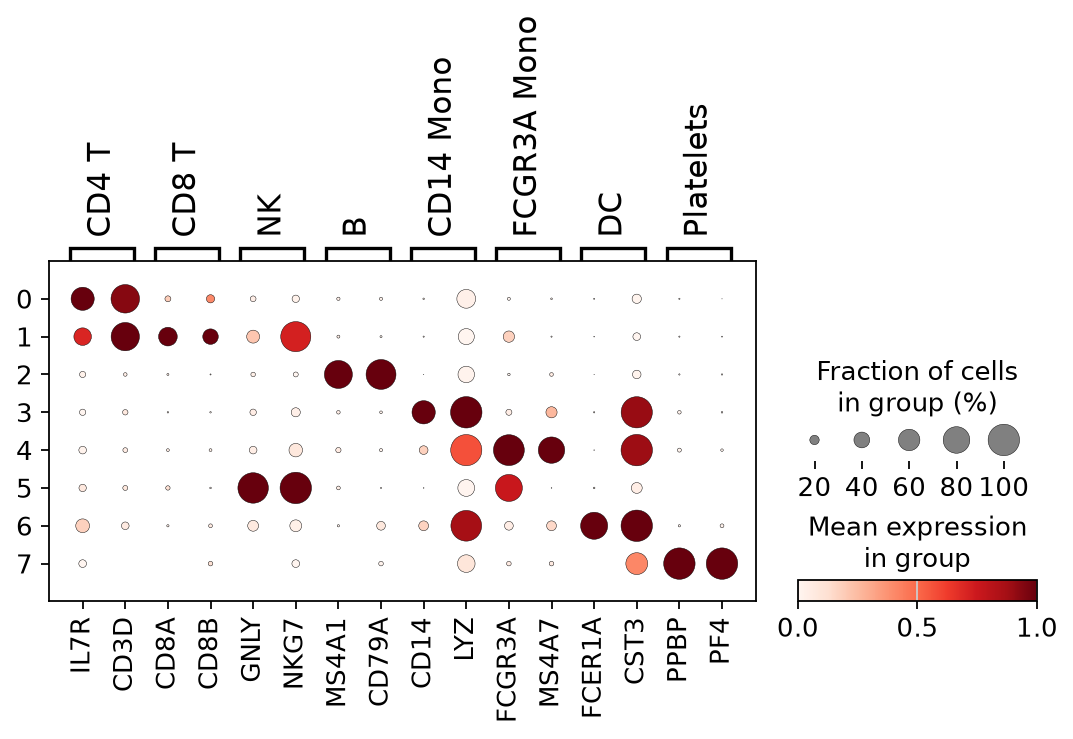

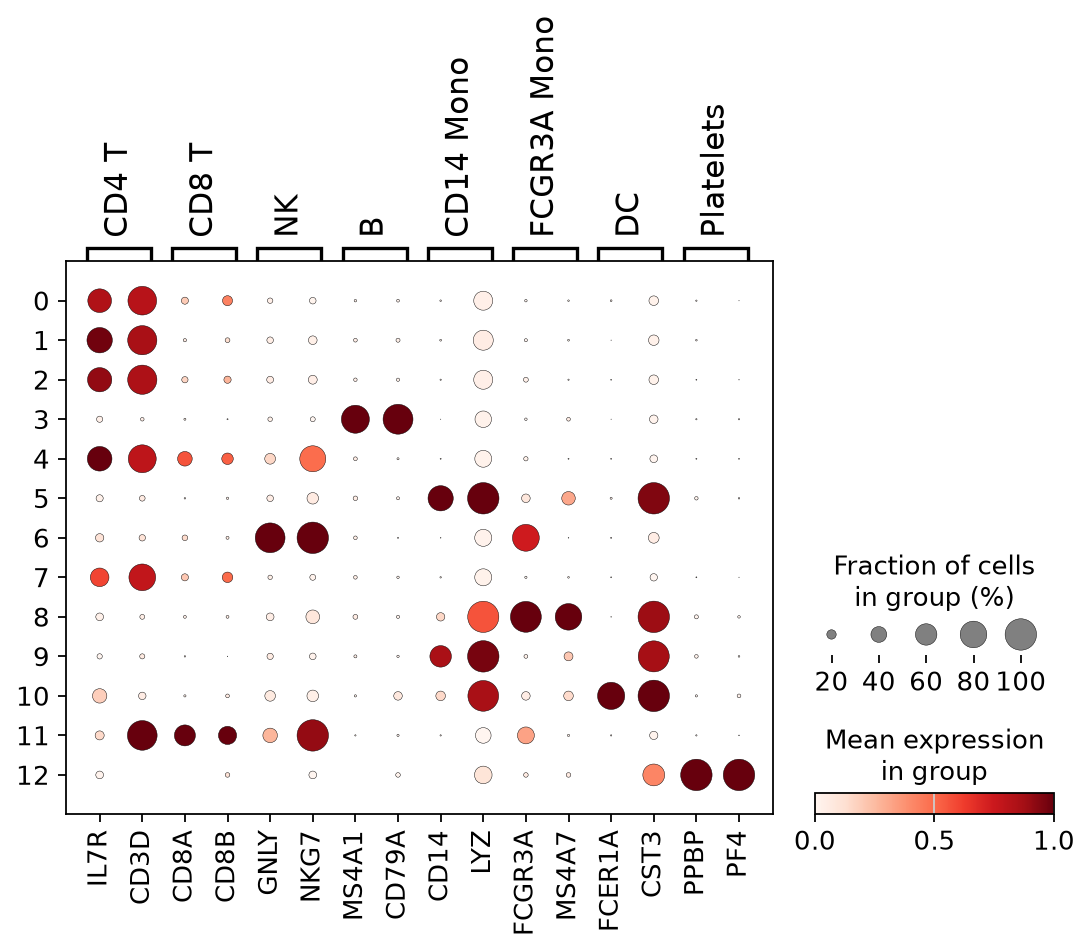

In [9]:
figure03 = scanpy.pl.dotplot(
    result_03,
    marker_genes,
    groupby='leiden',
    standard_scale='var',
    return_fig=True
)

figure03.savefig(
    figures_dir / "DOTPLOT_resolution_0.3.png",
    dpi=300,
    bbox_inches="tight"
)


figure07 = scanpy.pl.dotplot(
    result_07,
    marker_genes,
    groupby='leiden',
    standard_scale='var',
    return_fig=True
)

figure07.savefig(
    figures_dir / "DOTPLOT_resolution_0.7.png",
    dpi=300,
    bbox_inches="tight"
)


figure15 = scanpy.pl.dotplot(
    result_1_5,
    marker_genes,
    groupby='leiden',
    standard_scale='var',
    return_fig=True
)

figure15.savefig(
    figures_dir / "DOTPLOT_resolution_1.5.png",
    dpi=300,
    bbox_inches="tight"
)